# Credit Pre-Screening Engine — Loan Intake Optimisation

Credit analysts: G.Vignesh babu


## CBIM Problem Canvas

| Canvas element | Answer |
|---|---|
| **Situation (S)** | A mid-size private bank's retail lending unit receives ~3,000 unsecured personal-loan applications a month. Every application goes through a ~25-minute manual credit review, about 1,250 analyst hours a month. |
| **Complication (C)** | *Bank:* analyst time is spent on obvious cases, because close to half of applications end in decline and many are clear within a minute. *Analysts:* the queue is clogged with work that needs no judgement. *Applicants:* good customers wait in the same queue as hopeless applications, and clear declines wait for an answer they could have had instantly. Automating blindly is also risky: wrongly declining a good customer loses revenue, wrongly approving a risky one creates credit loss, and a model can quietly automate a bias. |
| **Question (Q)** | Which applications can **skip the full manual review**? The model will route every application into one of three lanes: **auto-decline** (model very confident it is a decline), **fast-track** (very confident it is an approval, light-touch check only) or **analyst review**. The bank decision is *which model and which two thresholds*. |
| **SSOT** | The single source of truth is `MUC02_Credit_PreScreening_Dataset.csv`: 12,000 applications, Apr–Sep 2026. The `decision` column records **what the credit analysts decided, not whether the loan was later repaid**. The model therefore learns the bank's *historical policy and habits* (including any inconsistency or bias), not true creditworthiness. "Wrongly declined" really means "declined by the model but approved by the credit team". |
| **Success definition** | **Hard limits (risk appetite):** at most **5%** of the auto-decline lane may be applications the team approved, and at most **5%** of the fast-track lane may be applications the team declined. **Objective:** within those limits, move the **maximum share** of applications (and analyst hours) out of the manual queue. **Guardrails:** no widening of the gender gap; a model whose declines the credit team can explain. Accuracy is *not* the success metric. |
| **Primary stakeholder** | The **Credit Policy Analyst**, who must defend the proposal to the **Head of Retail Lending** (owner of the risk limit). Also affected: the **credit analysts** (their work changes), **applicants** (especially gig workers, new-to-credit customers and women, who could be disadvantaged by a biased model) and **Compliance / Risk** (who must be able to explain declines). |

## PART 1: Baseline Pre-Screener (Steps 5.1–5.7)


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# One consistent look for every chart in the notebook
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, RED, GREEN, GREY = "#2F6DB5", "#C8423B", "#3E9B6B", "#8A8F98"

APPS_PER_MONTH = 3000        
REVIEW_MINUTES = 25         
def hours_for(share):
    """Analyst hours per month represented by a share (0-1) of applications."""
    return share * APPS_PER_MONTH * REVIEW_MINUTES / 60

### 5.1 Load, inspect and clean



In [3]:
df_raw = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")   
df = df_raw.copy()

In [4]:
df.shape

(12000, 19)

In [11]:
df.columns

Index(['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months',
       'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision'],
      dtype='object')

In [6]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  object 
 1   application_date       12000 non-null  object 
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  object 
 4   city                   12000 non-null  object 
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  object 
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  object 
 15  lo

In [5]:
df.isna().sum()

application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income            441
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
dtype: int64

In [9]:
print(df["decision"].value_counts())

decision
Approved    6353
Declined    5647
Name: count, dtype: int64


In [10]:
print(f"\nOverall approval rate: {(df['decision'] == 'Approved').mean():.1%}")


Overall approval rate: 52.9%


In [13]:
df.describe()

,age,city_tier,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_amount,tenure_months,proposed_emi
count,12000.000000,12000.000000,12000.000000,1.155900e+04,12000.000000,10961.000000,12000.000000,12000.000000,12000.000000,1.200000e+04,12000.000000,12000.00000
mean,33.153750,1.707917,3.774850,6.031486e+04,6273.166667,725.920080,114.880167,1.166000,0.775750,3.795925e+05,37.726000,15067.10000
std,7.058878,0.757728,3.149578,4.889083e+04,8526.169300,62.559023,77.329483,1.148356,1.227024,2.950731e+05,15.077131,15160.83502
min,21.000000,1.000000,0.000000,1.200000e+04,0.000000,479.000000,0.000000,0.000000,0.000000,5.000000e+04,12.000000,1200.00000
25%,28.000000,1.000000,1.500000,3.350000e+04,0.000000,684.000000,54.000000,0.000000,0.000000,1.750000e+05,24.000000,6000.00000
50%,33.000000,2.000000,3.000000,5.050000e+04,4000.000000,726.000000,114.000000,1.000000,0.000000,3.000000e+05,36.000000,10600.00000
75%,38.000000,2.000000,5.100000,7.475000e+04,8500.000000,769.000000,169.000000,2.000000,1.000000,4.900000e+05,48.000000,18700.00000
max,60.000000,3.000000,30.000000,1.656000e+06,96500.000000,890.000000,395.000000,8.000000,11.000000,2.500000e+06,60.000000,224500.00000


### missing monthly_income 

In [16]:
missing_income = df[df["monthly_income"].isnull()]
missing_income.shape

(441, 19)

In [17]:
missing_income["employment_type"].value_counts(normalize=True)

employment_type
Business Owner                0.514739
Self-Employed Professional    0.349206
Salaried                      0.111111
Gig / Contract                0.024943
Name: proportion, dtype: float64

In [18]:
df.groupby("employment_type")["monthly_income"].median()

employment_type
Business Owner                69500.0
Gig / Contract                28000.0
Salaried                      50000.0
Self-Employed Professional    75000.0
Name: monthly_income, dtype: float64

In [ ]:
missing_inc = df["monthly_income"].isna()
summary = pd.DataFrame({
    "share_of_all_applicants": df["employment_type"].value_counts(normalize=True),
    "share_of_missing_income_rows": df.loc[missing_inc, "employment_type"].value_counts(normalize=True),
    "pct_of_group_missing": df.groupby("employment_type")["monthly_income"].apply(lambda s: s.isna().mean()),
}).round(3)
print(summary)

print("\nApproval rate when income is missing vs present:")
print(df.groupby(missing_inc)["decision"].apply(lambda s: (s == "Approved").mean()).rename({False: "income present", True: "income missing"}).round(3))

print("\nMedian income by employment type (non-missing):")
print(df.groupby("employment_type")["monthly_income"].median())

                            share_of_all_applicants  share_of_missing_income_rows  pct_of_group_missing
employment_type                                                                                        
Business Owner                                0.146                         0.515                 0.130
Gig / Contract                                0.147                         0.025                 0.006
Salaried                                      0.588                         0.111                 0.007
Self-Employed Professional                    0.119                         0.349                 0.108

Approval rate when income is missing vs present:
monthly_income
income present    0.530
income missing    0.501
Name: decision, dtype: float64

Median income by employment type (non-missing):
employment_type
Business Owner                69500.0
Gig / Contract                28000.0
Salaried                      50000.0
Self-Employed Professional    75000.0
Name: monthly_i

### blank credit_score 

In [19]:
no_score = df[df["credit_score"].isnull()]
no_score.shape

(1039, 19)

In [20]:

no_score = df["credit_score"].isna()
print("Rows with blank credit_score:", no_score.sum(), f"({no_score.mean():.1%})")
print("\ncredit_history_months for those rows:")
print(df.loc[no_score, "credit_history_months"].describe()[["count", "min", "max"]])
print("\nCross-check: blank score vs zero credit history")
print(pd.crosstab(no_score.rename("score_blank"), (df["credit_history_months"] == 0).rename("history_is_0")))

Rows with blank credit_score: 1039 (8.7%)

credit_history_months for those rows:
count    1039.0
min         0.0
max         0.0
Name: credit_history_months, dtype: float64

Cross-check: blank score vs zero credit history
history_is_0  False  True 
score_blank               
False         10961      0
True              0   1039


## implausible monthly_income values 

There is a relationship, and it is the strongest evidence that these 20 values are annual incomes. I checked the 20 rows against their EMIs and loan approval decisions.

#### 1. Their proposed EMI looks normal, but their income looks absurd

| Metric | 20 Outlier Rows | All Other Applicants |
|---|---:|---:|
| Median Proposed EMI | 13,250 | 10,400 |
| Median Existing EMI | 2,500 | 4,000 |
| Median Loan Amount | 312,500 | 295,000 |

Their EMIs and loan amounts are within the ordinary range, but their incomes are 10 to 100 times higher. The number that is out of line is the income, not the loan.

#### 2. Using the income as typed, FOIR becomes impossible

FOIR (Fixed Obligation to Income Ratio) represents the share of income going toward EMIs.

- FOIR ranges from **0.5% to 4%**.
- Median FOIR is **2.4%**.

For example, one applicant has an EMI of 44,400 against a monthly income of 1,656,000.

No other applicant in the dataset has an FOIR anywhere near this low.

#### 3. After dividing the income by 12, they match everyone else

| Metric | 20 Rows (Income ÷ 12) | All Other Applicants |
|---|---:|---:|
| Median Proposed EMI ÷ Monthly Income | 0.18 | 0.21 |
| Median FOIR | 0.29 | 0.32 |

This is the key match. After dividing their income by 12, these 20 applicants have EMIs that account for approximately the same share of income as normal applicants.

If their incomes were genuinely 5 to 16 lakh per month, we would expect their EMI shares to be very small. However, that is not what we observe.

#### 4. Their approval rate is ordinary too

- **Approval Rate:** 55% for these 20 rows, compared with 53% for all other applicants.
- **Rejected Applications:** 9 out of 20 were declined.

A genuine 10-lakh-per-month earner would generally be expected to have a much lower EMI-to-income ratio. The observed approval and rejection patterns suggest that the credit team was evaluating applicants with ordinary income levels.

##### Who was declined?

Most declined applicants had either:

- A high corrected FOIR (0.44 and 0.48).
- A credit score below 650 (601 and 633).

This follows the same pattern observed in the rest of the dataset.

#### 5. Additional observation: All 20 applicants are salaried

One important detail is that all 20 outlier applicants belong to the **Salaried** category.

This supports the annual-income explanation. Salaried applicants generally know their annual package, so they may have entered their yearly income into a field intended for monthly income.


count      11559.0
mean       60315.0
std        48891.0
min        12000.0
25%        33500.0
50%        50500.0
75%        74750.0
max      1656000.0
Name: monthly_income, dtype: float64

Ten largest values:
[1656000. 1254000. 1212000. 1068000.  990000.  984000.  972000.  900000.
  870000.  702000.]


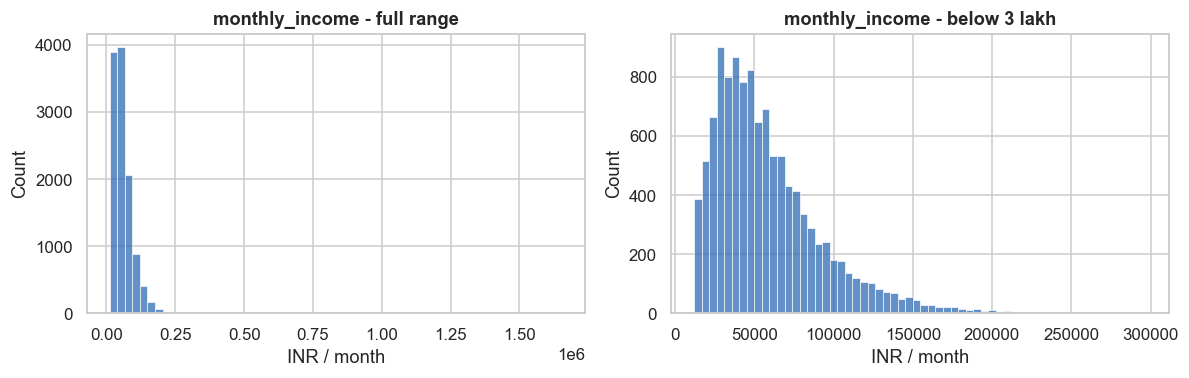


Values above 350,000: 20 rows
All exactly divisible by 12 (typical of annual figure): True
Implied monthly value if divided by 12:
min     29500.0
50%     58000.0
max    138000.0
Name: monthly_income, dtype: float64


In [15]:
print(df["monthly_income"].describe().round(0))
print("\nTen largest values:")
print(df["monthly_income"].nlargest(10).values)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df["monthly_income"].dropna(), bins=60, color=BLUE, ax=ax[0])
ax[0].set_title("monthly_income - full range"); ax[0].set_xlabel("INR / month")
sns.histplot(df.loc[df["monthly_income"] < 300_000, "monthly_income"], bins=60, color=BLUE, ax=ax[1])
ax[1].set_title("monthly_income - below 3 lakh"); ax[1].set_xlabel("INR / month")
plt.tight_layout(); plt.show()

ANNUAL_CUTOFF = 350_000
suspect = df["monthly_income"] > ANNUAL_CUTOFF
print(f"\nValues above {ANNUAL_CUTOFF:,}: {suspect.sum()} rows")
print("All exactly divisible by 12 (typical of annual figure):", (df.loc[suspect, "monthly_income"] % 12 == 0).all())
print("Implied monthly value if divided by 12:")
print((df.loc[suspect, "monthly_income"] / 12).describe().round(0)[["min", "50%", "max"]])

### Apply all three cleaning decisions 

- annual figures typed into a monthly field - divide by 12

- missing income median income of the same employment_type

In [23]:

df["income_was_annual"] = (df["monthly_income"] > ANNUAL_CUTOFF).astype(int)  
df.loc[df["income_was_annual"] == 1, "monthly_income"] /= 12


df["income_was_missing"] = df["monthly_income"].isna().astype(int)              
df["monthly_income"] = df.groupby("employment_type")["monthly_income"].transform(lambda s: s.fillna(s.median()))


print("Remaining nulls in monthly_income:", df["monthly_income"].isna().sum())
print("Max monthly_income after cleaning:", f"{df['monthly_income'].max():,.0f}")
print("Rows kept:", len(df), "of", len(df_raw))

Remaining nulls in monthly_income: 0
Max monthly_income after cleaning: 349,000
Rows kept: 12000 of 12000


In [24]:
df.isnull().sum()

application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income              0
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
income_was_annual           0
income_was_missing          0
dtype: int64

### 5.1 Findings: cleaning decision log

The target is fairly balanced: **52.9% Approved / 47.1% Declined**. A model that always says "Approved" would already be 52.9% accurate, so accuracy alone is a weak yardstick (see 5.4).

| # | Issue | What the data shows | Decision | Why |
|---|---|---|---|---|
| 1 | **Missing `monthly_income`** (441 rows, 3.7%) | Not random. **Business Owners** (13.0% of the group blank) and **Self-Employed Professionals** (10.8%) account for 86% of the blanks, against under 1% for Salaried and Gig. Approval is similar with or without income (50.1% vs 53.0%). | Fill with the **median income of the same `employment_type`** | Non-salaried applicants have no payslip, so income is self-declared and sometimes left blank. A single overall median (about 50,500) would understate typical Business Owner / Self-Employed incomes (about 70,000+), and the mean is dragged up by outliers. The group median is robust and respects the pattern. Dropping 441 rows would remove people from exactly the groups we care about. |
| 2 | **Blank `credit_score`** (1,039 rows, 8.7%) | **Every one** has `credit_history_months = 0`, and every applicant with zero history has a blank score (perfect overlap). | **Keep**; flag them as `is_ntc` (new-to-credit) in 5.3, fill the score with the median *inside the model* in 5.4 | They are not errors: they are applicants with **no credit history**. Their approval rate (53.9%, see 5.2) shows analysts do judge them on other factors. Dropping them would erase ~9% of customers and blind the model to a whole customer type. |
| 3 | **Implausible `monthly_income`** (max 1,656,000, i.e. 16.6 lakh a month) | 20 values above 350,000, **all exact multiples of 12**. Divided by 12 they become 29,500–138,000 (median 58,000), right inside the normal range. | **Divide by 12** for values above 350,000 (and keep an audit flag) | Most likely explanation: **annual** income typed into a monthly field. Left alone, these applicants would get an absurdly low FOIR and loan-to-income and look artificially safe, and they would distort scaling. Dropping loses real customers; capping would invent a wrong number. |

### 5.2 What drives approval today?


            approval_rate  applications
score_band                             
Below 600             2.0           246
600-649               3.2           933
650-699              32.5          2529
700-749              54.4          3377
750-799              77.2          2526
800+                 85.2          1350
No score             53.9          1039

                            approval_rate  applications
employment_type                                        
Salaried                             58.4          7057
Business Owner                       51.2          1749
Self-Employed Professional           50.6          1428
Gig / Contract                       34.9          1766


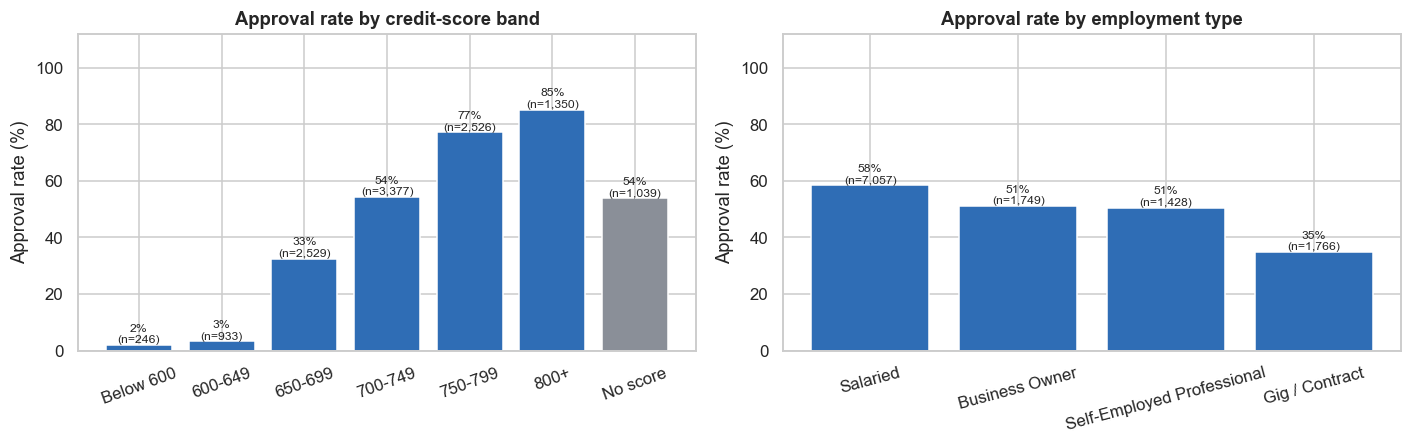

In [27]:
df["approved"] = (df["decision"] == "Approved").astype(int)

score_bins = [0, 600, 650, 700, 750, 800, 1000]
score_labels = ["Below 600", "600-649", "650-699", "700-749", "750-799", "800+"]
df["score_band"] = pd.cut(df["credit_score"], bins=score_bins, labels=score_labels, right=False)
df["score_band"] = df["score_band"].cat.add_categories("No score").fillna("No score")
band_order = score_labels + ["No score"]

by_score = df.groupby("score_band", observed=True)["approved"].agg(approval_rate="mean", applications="size").reindex(band_order)
print((by_score.assign(approval_rate=by_score["approval_rate"] * 100)).round(1))

by_emp = df.groupby("employment_type")["approved"].agg(approval_rate="mean", applications="size").sort_values("approval_rate", ascending=False)
print()
print((by_emp.assign(approval_rate=by_emp["approval_rate"] * 100)).round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bars = ax[0].bar(by_score.index.astype(str), by_score["approval_rate"] * 100, color=[BLUE] * 6 + [GREY])
ax[0].bar_label(bars, labels=[f"{v:.0f}%\n(n={n:,})" for v, n in zip(by_score["approval_rate"] * 100, by_score["applications"])], fontsize=8)
ax[0].set_title("Approval rate by credit-score band"); ax[0].set_ylabel("Approval rate (%)"); ax[0].set_ylim(0, 112)
ax[0].tick_params(axis="x", rotation=20)

bars = ax[1].bar(by_emp.index, by_emp["approval_rate"] * 100, color=BLUE)
ax[1].bar_label(bars, labels=[f"{v:.0f}%\n(n={n:,})" for v, n in zip(by_emp["approval_rate"] * 100, by_emp["applications"])], fontsize=8)
ax[1].set_title("Approval rate by employment type"); ax[1].set_ylabel("Approval rate (%)"); ax[1].set_ylim(0, 112)
ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

In [28]:
# A finer look at where the credit-score "cliff" sits (25-point bins)
fine = pd.cut(df["credit_score"], bins=range(450, 925, 25), right=False)
fine_tbl = df.groupby(fine, observed=True)["approved"].agg(["mean", "size"]).rename(columns={"mean": "approval_rate", "size": "n"})
print(fine_tbl.round(3).T.to_string())

credit_score   [475, 500)  [500, 525)  [525, 550)  [550, 575)  [575, 600)  [600, 625)  [625, 650)  [650, 675)  [675, 700)  [700, 725)  [725, 750)  [750, 775)  [775, 800)  [800, 825)  [825, 850)  [850, 875)  [875, 900)
approval_rate         0.0         0.0         0.0         0.0        0.03        0.03       0.033       0.278       0.358       0.512       0.575       0.731       0.826       0.867       0.837       0.864       0.775
n                     5.0         7.0        18.0        47.0      169.00      362.00     571.000    1034.000    1495.000    1689.000    1688.000    1439.000    1087.000     697.000     387.000     177.000      89.000


### 5.2 Findings

* **There is a cliff at 650.** Approval is **2.0%** below 600 and **3.2%** for 600–649, then jumps to **32.5%** for 650–699, **54.4%** (700–749), **77.2%** (750–799) and **85.2%** (800+). The 25-point view confirms the break sits exactly at 650 (about 3% just under it, about 28% just over).
* **Unwritten policy:** the credit team behaves as if there is a **minimum score of about 650**. Below it, applications are almost never approved (1,179 applications, 9.8% of the book). Above it, the score works as a sliding scale rather than a pass mark.
* **No-score (new-to-credit) applicants** are approved **53.9%** of the time, close to the overall average and the same as the 700–749 band. Analysts do *not* reject thin-file customers by reflex; they decide on other evidence (income, FOIR, job). This is why they must stay in the data.
* **Employment type:** Salaried 58.4%, Business Owner 51.2%, Self-Employed Professional 50.6%, but **Gig / Contract only 34.9%**, about 23 points below salaried. That gap is either a direct penalty or the effect of lower income and higher FOIR; either way it must be examined for fairness in 5.6.

**So what:** a large block of obvious declines (score below 650) exists, and any sensible model should find it, which is where the auto-decline lane will get its volume.

### 5.3 Engineer the affordability features

- Create three columns: `foir = (existing_emi + proposed_emi) / monthly_income`, `loan_to_income = loan_amount / (monthly_income × 12)`, and `is_ntc` = 1 if the applicant has no credit score, else 0.
* Group FOIR into bands **<30%, 30–40%, 40–50%, 50–55%, >55%** and plot approval rate per band.

            foir  loan_to_income     is_ntc
count  12000.000       12000.000  12000.000
mean       0.358           0.531      0.087
std        0.207           0.225      0.281
min        0.013           0.031      0.000
25%        0.215           0.347      0.000
50%        0.317           0.519      0.000
75%        0.450           0.699      0.000
max        3.393           2.778      1.000

           approval_rate  applications
foir_band                             
Below 30%           65.5          5487
30-40%              59.0          2500
40-50%              47.8          1767
50-55%              32.4           531
Above 55%           15.6          1715


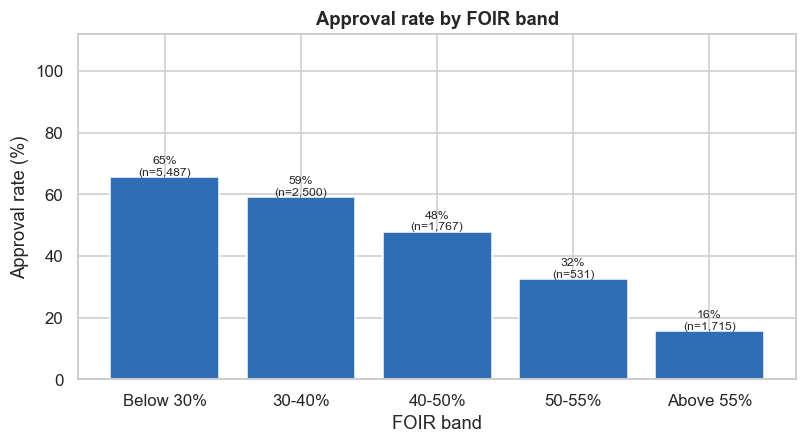

In [29]:
df["foir"] = (df["existing_emi"] + df["proposed_emi"]) / df["monthly_income"]
df["loan_to_income"] = df["loan_amount"] / (df["monthly_income"] * 12)
df["is_ntc"] = df["credit_score"].isna().astype(int)

print(df[["foir", "loan_to_income", "is_ntc"]].describe().round(3))

foir_bins = [0, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = ["Below 30%", "30-40%", "40-50%", "50-55%", "Above 55%"]
df["foir_band"] = pd.cut(df["foir"], bins=foir_bins, labels=foir_labels, right=False)

by_foir = df.groupby("foir_band", observed=True)["approved"].agg(approval_rate="mean", applications="size")
print()
print((by_foir.assign(approval_rate=by_foir["approval_rate"] * 100)).round(1))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(by_foir.index.astype(str), by_foir["approval_rate"] * 100, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.0f}%\n(n={n:,})" for v, n in zip(by_foir["approval_rate"] * 100, by_foir["applications"])], fontsize=8)
ax.set_title("Approval rate by FOIR band"); ax.set_ylabel("Approval rate (%)"); ax.set_xlabel("FOIR band"); ax.set_ylim(0, 112)
plt.tight_layout(); plt.show()

In [30]:
# Finer FOIR view (5-point bins) to locate the cliff for the policy proposal
fine = pd.cut(df["foir"], bins=np.arange(0, 1.05, 0.05), right=False)
fine_tbl = df.groupby(fine, observed=True)["approved"].agg(["mean", "size"]).rename(columns={"mean": "approval_rate", "size": "n"})
print(fine_tbl.round(3).T.to_string())

foir           [0.0, 0.05)  [0.05, 0.1)  [0.1, 0.15)  [0.15, 0.2)  [0.2, 0.25)  [0.25, 0.3)  [0.3, 0.35)  [0.35, 0.4)  [0.4, 0.45)  [0.45, 0.5)  [0.5, 0.55)  [0.55, 0.6)  [0.6, 0.65)  [0.65, 0.7)  [0.7, 0.75)  [0.75, 0.8)  [0.8, 0.85)  [0.85, 0.9)  [0.9, 0.95)  [0.95, 1.0)
approval_rate        0.692        0.639        0.663        0.651        0.652         0.66        0.603        0.574        0.491        0.461        0.324        0.164        0.129        0.137        0.159        0.167        0.168        0.139        0.181        0.189
n                   13.000      471.000      837.000     1223.000     1456.000      1522.00     1340.000     1125.000     1004.000      763.000      531.000      402.000      278.000      234.000      164.000      126.000      113.000      108.000       94.000       53.000


### 5.3 Findings

* Approval falls steadily as FOIR rises: **65.5%** (below 30%) → **59.0%** → **47.8%** (40–50%) → **32.4%** (50–55%) → **15.6%** (above 55%). The 5-point view shows the sharpest step is at **55%**: 32.4% for 50–55% drops to about 16% for 55–60% and then stays flat at 13–19% all the way to 100%.
* **Proposed policy:** a **FOIR cap of 55%** for the standard approval path, with **50%** as an "amber" level above which the score must be strong. Approval is *not* zero above 55% (15.6%), so analysts do grant exceptions today. A hard 55% cap would be slightly tighter than current practice and should be introduced as the pre-screen limit, with a senior-exception route.
* FOIR drifts downward even below 50% rather than breaking at one point, so the model should use FOIR as a **continuous** feature, not just a pass/fail rule.

### 5.4 Build the logistic regression pre-screener


In [31]:
num_features = ["credit_score", "is_ntc", "foir", "loan_to_income", "delinquencies_24m",
                "num_active_loans", "years_in_current_job", "age", "tenure_months", "city_tier"]
cat_features = ["employment_type", "loan_purpose"]
features = num_features + cat_features

df["declined"] = (df["decision"] == "Declined").astype(int)        
X, y = df[features], df["declined"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Decline rate - train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (9600, 12)  Test: (2400, 12)
Decline rate - train: 0.471 | test: 0.470


Accuracy: 0.791 | Precision (Declined): 0.791 | Recall (Declined): 0.755

                   Predicted Approved  Predicted Declined
Actually Approved                1046                 225
Actually Declined                 277                 852

Creditworthy (approved) applicants wrongly predicted Declined: 225 of 1271 approved = 17.7%
Declined applicants the model would have waved through: 277 of 1129 declined = 24.5%


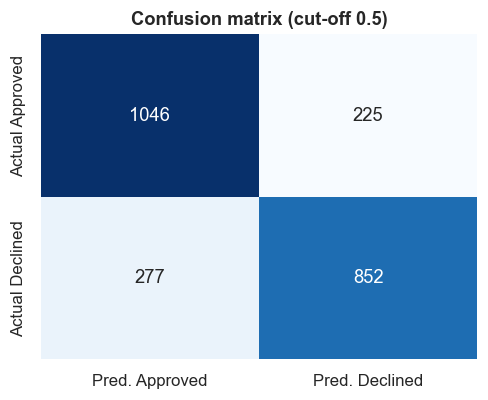

In [32]:

median_score = X_train["credit_score"].median()
def prepare(frame):
    frame = frame.copy()
    frame["credit_score"] = frame["credit_score"].fillna(median_score)      
    return pd.get_dummies(frame, columns=cat_features)

Xtr, Xte = prepare(X_train), prepare(X_test)
Xte = Xte.reindex(columns=Xtr.columns, fill_value=0)

scaler = StandardScaler().fit(Xtr[num_features])
Xtr_s, Xte_s = Xtr.copy(), Xte.copy()
Xtr_s[num_features] = scaler.transform(Xtr[num_features])
Xte_s[num_features] = scaler.transform(Xte[num_features])

logit = LogisticRegression(max_iter=1000, random_state=42).fit(Xtr_s.astype(float), y_train)
p_decline = logit.predict_proba(Xte_s.astype(float))[:, 1]
pred = (p_decline >= 0.5).astype(int)

cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
acc, prec, rec = accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred)
print(f"Accuracy: {acc:.3f} | Precision (Declined): {prec:.3f} | Recall (Declined): {rec:.3f}")
print()
print(pd.DataFrame(cm, index=["Actually Approved", "Actually Declined"], columns=["Predicted Approved", "Predicted Declined"]))
print(f"\nCreditworthy (approved) applicants wrongly predicted Declined: {fp} of {tn + fp} approved = {fp / (tn + fp):.1%}")
print(f"Declined applicants the model would have waved through: {fn} of {fn + tp} declined = {fn / (fn + tp):.1%}")

fig, ax = plt.subplots(figsize=(4.6, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Pred. Approved", "Pred. Declined"], yticklabels=["Actual Approved", "Actual Declined"])
ax.set_title("Confusion matrix (cut-off 0.5)")
plt.tight_layout(); plt.show()



In [33]:
coefs = pd.Series(logit.coef_[0], index=Xtr_s.columns)
top5 = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(5)
print("\nTop 5 coefficients by size (features are standardised, so they are comparable):")
print(top5.round(3))
print("\nFull coefficient table:")
print(coefs.sort_values().round(3).to_string())


Top 5 coefficients by size (features are standardised, so they are comparable):
foir                              1.221
credit_score                     -1.009
delinquencies_24m                 0.979
employment_type_Gig / Contract    0.620
employment_type_Salaried         -0.445
dtype: float64

Full coefficient table:
credit_score                                 -1.009
employment_type_Salaried                     -0.445
loan_to_income                               -0.193
loan_purpose_Consumer Durables               -0.158
years_in_current_job                         -0.144
loan_purpose_Education                       -0.130
age                                          -0.045
employment_type_Self-Employed Professional   -0.043
loan_purpose_Medical                         -0.030
loan_purpose_Home Renovation                 -0.028
employment_type_Business Owner               -0.023
city_tier                                     0.016
loan_purpose_Travel                           0.038
loa

### 5.4 Findings

**Headline numbers (test set, 2,400 applications, cut-off 0.5):** accuracy **79.1%**, precision for Declined **79.1%**, recall for Declined **75.5%**.

**The confusion matrix in business language**

| | Predicted Approved | Predicted Declined |
|---|---|---|
| **Actually Approved** | 1,046 | **225** |
| **Actually Declined** | **277** | 852 |

* **225 of 1,271 creditworthy applicants (17.7%) would be wrongly declined** at the default 0.5 cut-off, nearly one in five good customers turned away. This is the number the bank cares about, and it is why 0.5 is not usable as an auto-decline rule.
* **277 of 1,129 declined applicants (24.5%)** would be waved through as "not a decline". Harmless at this stage (analysts still review them), but it shows the model misses a quarter of declines.
* Accuracy of 79% sounds decent, but it hides that the model is not safe to act on at 0.5.

**Top five coefficients, explained to a credit analyst** (features are standardised, so sizes are comparable; positive = pushes toward decline)

| Factor | Coefficient | Meaning |
|---|---|---|
| **FOIR** | **+1.22** | The strongest driver. Each step of about 0.2 more of income going to EMIs multiplies the odds of decline by roughly 3.4. |
| **Credit score** | **−1.01** | Higher score protects the application. About 60 points more score cuts the odds of decline to roughly a third. |
| **Delinquencies (24m)** | **+0.98** | Every extra late or missed payment (about 1.2 per SD) pushes strongly toward decline, roughly 2.7× the odds. |
| **Gig / Contract work** | **+0.62** | Being a gig or contract worker pushes toward decline *even after* score and FOIR are accounted for. |
| **Salaried** | **−0.45** | Salaried status pushes toward approval. |

Just outside the top five: **new-to-credit (+0.38)** and **Debt Consolidation purpose (+0.35)** also lean toward decline; `loan_to_income`, job tenure, age and city tier barely matter.

### 5.5 Set the auto-decline threshold


In [43]:
thresholds = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]
rows = []
for t in thresholds:
    auto = p_decline >= t
    rows.append({
        "threshold": t,
        "auto_declined_pct": auto.mean() * 100,
        "n_auto_declined": int(auto.sum()),
        "wrongly_declined_pct": (y_test[auto] == 0).mean() * 100 if auto.any() else np.nan,
        "n_wrongly_declined": int((y_test[auto] == 0).sum()),
    })
thr_table = pd.DataFrame(rows).set_index("threshold")
print(thr_table.round(2))


           auto_declined_pct  n_auto_declined  wrongly_declined_pct  n_wrongly_declined
threshold                                                                              
0.50                   44.88             1077                 20.89                 225
0.60                   37.58              902                 16.85                 152
0.70                   30.75              738                 12.06                  89
0.80                   23.46              563                  7.10                  40
0.85                   19.67              472                  5.93                  28
0.90                   15.21              365                  4.66                  17
0.95                   10.00              240                  2.08                   5


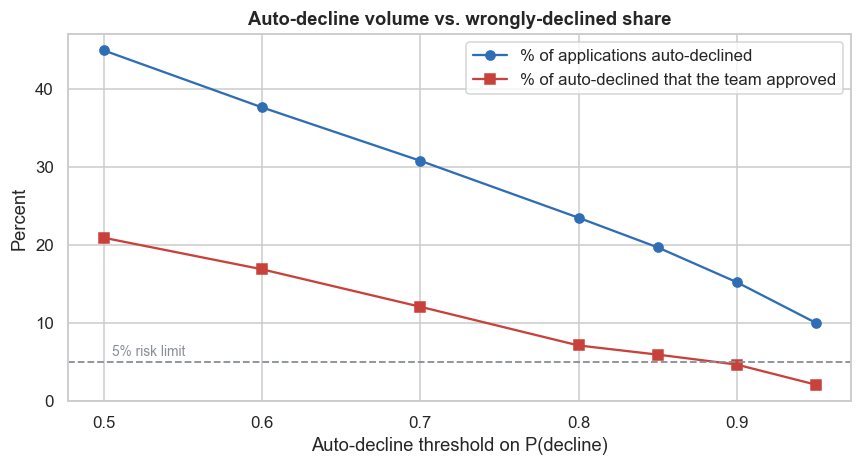

In [44]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(thr_table.index, thr_table["auto_declined_pct"], marker="o", color=BLUE, label="% of applications auto-declined")
ax.plot(thr_table.index, thr_table["wrongly_declined_pct"], marker="s", color=RED, label="% of auto-declined that the team approved")
ax.axhline(5, color=GREY, ls="--", lw=1.2); ax.text(0.505, 5.8, "5% risk limit", color=GREY, fontsize=9)
ax.set_xlabel("Auto-decline threshold on P(decline)"); ax.set_ylabel("Percent")
ax.set_title("Auto-decline volume vs. wrongly-declined share"); ax.legend()
plt.tight_layout(); plt.show()

In [45]:
ok = thr_table[thr_table["wrongly_declined_pct"] <= 5]
CHOSEN_T = ok["auto_declined_pct"].idxmax()
chosen = thr_table.loc[CHOSEN_T]
print(f"\nChosen threshold: {CHOSEN_T}  ->  auto-declines {chosen['auto_declined_pct']:.1f}% of applications, "
      f"{chosen['wrongly_declined_pct']:.1f}% of them wrongly ({int(chosen['n_wrongly_declined'])} of {int(chosen['n_auto_declined'])} in the test set)")

freed_apps = chosen["auto_declined_pct"] / 100 * APPS_PER_MONTH
print(f"Monthly impact: ~{freed_apps:,.0f} of {APPS_PER_MONTH:,} applications no longer need manual review "
      f"= ~{hours_for(chosen['auto_declined_pct'] / 100):,.0f} of {hours_for(1):,.0f} analyst hours per month freed")


Chosen threshold: 0.9  ->  auto-declines 15.2% of applications, 4.7% of them wrongly (17 of 365 in the test set)
Monthly impact: ~456 of 3,000 applications no longer need manual review = ~190 of 1,250 analyst hours per month freed


### 5.5 Findings

| Threshold on P(decline) | % auto-declined | % of those wrongly declined |
|---|---|---|
| 0.50 | 44.9% | 20.9% |
| 0.60 | 37.6% | 16.9% |
| 0.70 | 30.8% | 12.1% |
| 0.80 | 23.5% | 7.1% |
| 0.85 | 19.7% | 5.9% (over the limit) |
| **0.90** | **15.2%** | **4.7% (within the limit)** |
| 0.95 | 10.0% | 2.1% |

**Chosen threshold: 0.90.** It is the lowest cut-off that meets the 5% rule (0.85 misses it at 5.9%), so it auto-declines the most applications while staying within the bank's risk appetite.

**Monthly business case:** 15.2% of 3,000 = **about 456 applications a month** no longer need a manual review, which frees **about 190 of 1,250 analyst hours** a month (25 minutes × 456).


### 5.6 Fairness check



In [47]:
fair = df.copy()
print("Historical approval rate by gender (overall)")
print((fair.groupby("gender")["approved"].mean() * 100).round(1).to_string())
print("\n   ... and within each employment type (%)")
print((fair.pivot_table(index="employment_type", columns="gender", values="approved", aggfunc="mean") * 100).round(1))

Historical approval rate by gender (overall)
gender
Female    50.4
Male      54.1

   ... and within each employment type (%)
gender                      Female  Male
employment_type                         
Business Owner                51.6  51.1
Gig / Contract                34.6  35.2
Salaried                      56.8  59.1
Self-Employed Professional    47.6  52.0


In [49]:
print("\n Income and job-mix by gender")
print(fair.groupby("gender").agg(
    median_monthly_income=("monthly_income", "median"),
    share_gig_contract=("employment_type", lambda s: (s == "Gig / Contract").mean() * 100),
    mean_foir=("foir", "mean"),
    mean_credit_score=("credit_score", "mean"),
    share_no_score=("is_ntc", lambda s: s.mean() * 100),
).round(2))
print("\n   Applicant mix (% of each gender):")
print((pd.crosstab(fair["gender"], fair["employment_type"], normalize="index") * 100).round(1))


 Income and job-mix by gender
        median_monthly_income  share_gig_contract  mean_foir  mean_credit_score  share_no_score
gender                                                                                         
Female                45000.0               21.37       0.36             724.05            8.54
Male                  55000.0               11.64       0.36             726.79            8.71

   Applicant mix (% of each gender):
employment_type  Business Owner  Gig / Contract  Salaried  Self-Employed Professional
gender                                                                               
Female                      9.7            21.4      56.7                        12.2
Male                       16.8            11.6      59.8                        11.7


In [53]:
print("\n Model auto-decline rate by gender at threshold", CHOSEN_T, "(test set)")
test_view = df.loc[X_test.index, ["gender", "declined"]].copy()
test_view["auto_declined"] = (p_decline >= CHOSEN_T).astype(int)
test_view["wrongly_auto_declined"] = ((test_view["auto_declined"] == 1) & (test_view["declined"] == 0)).astype(int)
g = test_view.groupby("gender").agg(applications=("declined", "size"),
                                    historical_decline_rate=("declined", "mean"),
                                    auto_decline_rate=("auto_declined", "mean"),
                                    n_auto_declined=("auto_declined", "sum"),
                                    n_wrongly_auto_declined=("wrongly_auto_declined", "sum"))
g["wrong_share_of_auto_declined"] = g["n_wrongly_auto_declined"] / g["n_auto_declined"]
print((g.assign(historical_decline_rate=g["historical_decline_rate"] * 100, auto_decline_rate=g["auto_decline_rate"] * 100,
                wrong_share_of_auto_declined=g["wrong_share_of_auto_declined"] * 100)).round(1))




 Model auto-decline rate by gender at threshold 0.9 (test set)
        applications  historical_decline_rate  auto_decline_rate  n_auto_declined  n_wrongly_auto_declined  wrong_share_of_auto_declined
gender                                                                                                                                  
Female           750                     49.7               15.6              117                        4                           3.4
Male            1650                     45.8               15.0              248                       13                           5.2


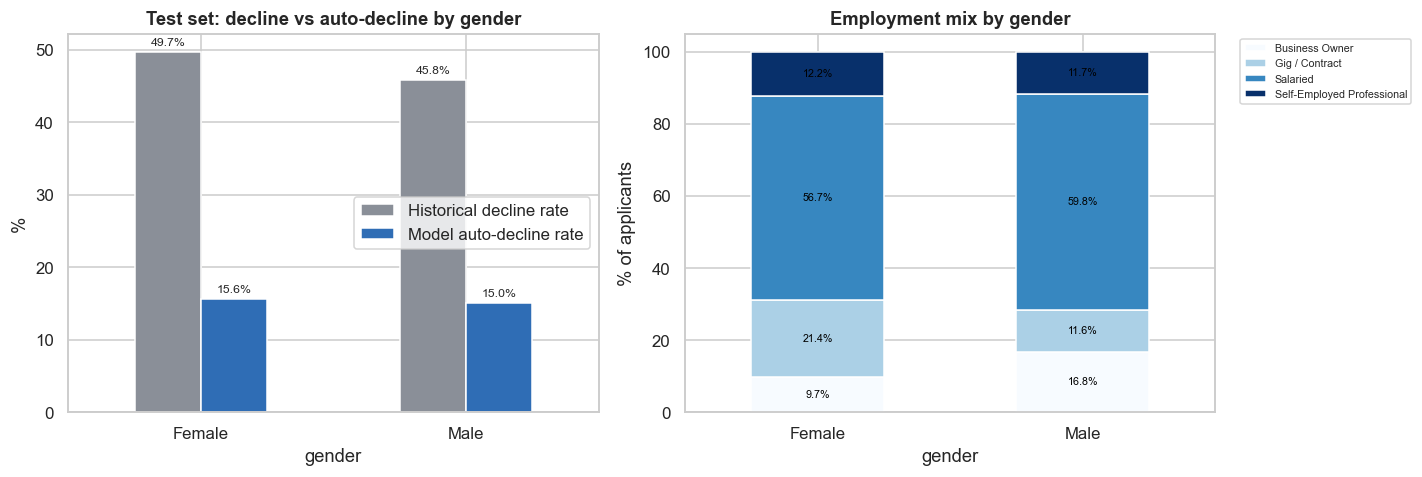

In [55]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))


tmp = pd.DataFrame({
    "Historical decline rate": g["historical_decline_rate"] * 100,
    "Model auto-decline rate": g["auto_decline_rate"] * 100
})

tmp.plot.bar(ax=ax[0], color=[GREY, BLUE], rot=0)

ax[0].set_title("Test set: decline vs auto-decline by gender")
ax[0].set_ylabel("%")


for container in ax[0].containers:
    ax[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=8)


mix = pd.crosstab(
    fair["gender"],
    fair["employment_type"],
    normalize="index"
) * 100

mix.plot.bar(
    stacked=True,
    ax=ax[1],
    rot=0,
    colormap="Blues"
)

ax[1].set_title("Employment mix by gender")
ax[1].set_ylabel("% of applicants")


for container in ax[1].containers:
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 5 else ""
        for bar in container
    ]
    ax[1].bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=7,
        color="black"
    )

ax[1].legend(
    fontsize=7,
    loc="upper right",
    bbox_to_anchor=(1.38, 1)
)
plt.tight_layout()
plt.show()

### 5.6 Findings

| Check | Female | Male |
|---|---|---|
| Historical approval rate (all) | 50.4% | 54.1% |
| ...Salaried / Self-Employed / Business Owner / Gig | 56.8 / 47.6 / 51.6 / 34.6% | 59.1 / 52.0 / 51.1 / 35.2% |
| Median monthly income | 45,000 | 55,000 |
| Share in Gig / Contract work | 21.4% | 11.6% |
| Average FOIR · average credit score | 0.36 · 724 | 0.36 · 727 |
| Model auto-decline rate (test, threshold 0.90) | 15.6% | 15.0% |

**Answer.** Yes, there is a historical gap: women were approved 3.7 points less often (50.4% vs 54.1%). A large part comes from the applicant mix: women have a lower median income (45,000 vs 55,000) and are almost twice as likely to be gig workers (21.4% vs 11.6%), the group with the lowest approval (about 35%), and within Business Owner and Gig the gaps are under 1 point, though a residual gap remains among Salaried (2.3 points) and Self-Employed Professionals (4.4 points) that these columns cannot explain. The model does not widen it: the auto-decline gap is 0.6 points (15.6% vs 15.0%), smaller than the 3.9-point gap in historical declines, though the 750 women in the test set make this a rough estimate. Gender should never be a feature in a credit model, but removing it does not solve the problem, because `employment_type` and income-based features act as **proxies** that carry the gap, so outcomes must be monitored by gender after launch.

## 5.7 Interim Briefing (Part 1)

For the **logistic regression**, I recommend auto-declining only when **P(decline) ≥ 0.90**. On the test set this auto-declines **15.2% of applications**, of which **4.7%** were ones the credit team approved, inside the 5% limit. At 3,000 applications a month that frees about **456 applications and 190 analyst hours (out of 1,250)**. The weakness I most want Part 2 to address is that this model can only *decline*: it offers nothing for clear approvals, and at 0.5 it wrongly flags 17.7% of good customers, so it needs a very high threshold to be safe and leaves most of the queue untouched. Part 2 asks whether a better-ranking model and a second, **fast-track** lane can safely automate much more.

## PART 2: Model Comparison & Two-Lane Design (Steps 5.8–5.11)



### 5.8 Rebuild the baseline as a pipeline


In [70]:
class CreditFeatureBuilder(BaseEstimator, TransformerMixin):
    """Turns RAW application rows (exactly as in the CSV) into model-ready columns.

    Repeats the Step 5.1 / 5.3 logic inside the pipeline:
      * annual income typed into the monthly field (> cutoff)  -> divide by 12
      * missing monthly_income -> median of the same employment_type (learned from TRAINING rows only)
      * adds foir, loan_to_income and is_ntc
    """
    def __init__(self, annual_cutoff=350_000):
        self.annual_cutoff = annual_cutoff

    def _monthly(self, income):
        return income.where(income <= self.annual_cutoff, income / 12)

    def fit(self, X, y=None):
        inc = self._monthly(X["monthly_income"])
        self.median_by_type_ = inc.groupby(X["employment_type"]).median()
        self.median_overall_ = inc.median()
        return self

    def transform(self, X):
        X = X.copy()
        inc = self._monthly(X["monthly_income"])
        fallback = X["employment_type"].map(self.median_by_type_).fillna(self.median_overall_)
        X["monthly_income"] = inc.fillna(fallback)
        X["foir"] = (X["existing_emi"] + X["proposed_emi"]) / X["monthly_income"]
        X["loan_to_income"] = X["loan_amount"] / (X["monthly_income"] * 12)
        X["is_ntc"] = X["credit_score"].isna().astype(int)
        return X


def build_pipeline(classifier):
    """One object: raw rows in -> decline probability out."""
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ])
    return Pipeline([("features", CreditFeatureBuilder()), ("prep", prep), ("clf", classifier)])


# Same split as Step 5.4, but taken from the RAW csv rows (same row index -> same applicants)
raw_train, raw_test = df_raw.loc[X_train.index], df_raw.loc[X_test.index]
print("Raw train / test rows:", raw_train.shape, raw_test.shape)

Raw train / test rows: (9600, 19) (2400, 19)


In [73]:
pipe_lr = build_pipeline(LogisticRegression(max_iter=1000, random_state=42))
pipe_lr.fit(raw_train, y_train)

p_decline_pipe = pipe_lr.predict_proba(raw_test)[:, 1]
pred_pipe = (p_decline_pipe >= 0.5).astype(int)

print("                         Step 5.4      Pipeline (5.8)")
print(f"Accuracy               : {acc:.4f}        {accuracy_score(y_test, pred_pipe):.4f}")
print(f"Precision (Declined)   : {prec:.4f}        {precision_score(y_test, pred_pipe):.4f}")
print(f"Recall (Declined)      : {rec:.4f}        {recall_score(y_test, pred_pipe):.4f}")
print(f"Confusion matrix 5.4   : {confusion_matrix(y_test, pred).tolist()}")
print(f"Confusion matrix pipe  : {confusion_matrix(y_test, pred_pipe).tolist()}")
print(f"\nLargest difference in predicted probability between the two builds: {np.abs(p_decline - p_decline_pipe).max():.5f}")
print("Predictions that flip class:", int((pred != pred_pipe).sum()))
print("\nIncome medians learned by the pipeline (train rows only):")
print(pipe_lr.named_steps["features"].median_by_type_)

                         Step 5.4      Pipeline (5.8)
Accuracy               : 0.7908        0.7904
Precision (Declined)   : 0.7911        0.7909
Recall (Declined)      : 0.7547        0.7538
Confusion matrix 5.4   : [[1046, 225], [277, 852]]
Confusion matrix pipe  : [[1046, 225], [278, 851]]

Largest difference in predicted probability between the two builds: 0.01465
Predictions that flip class: 1

Income medians learned by the pipeline (train rows only):
employment_type
Business Owner                71000.0
Gig / Contract                28500.0
Salaried                      50500.0
Self-Employed Professional    75250.0
Name: monthly_income, dtype: float64


In [72]:
# Five most recent applications, passed in as RAW rows straight from the csv (blanks and all)
last5 = df_raw.tail(5)
out = last5[["application_id", "application_date", "employment_type", "monthly_income", "credit_score", "decision"]].copy()
out["P(decline)"] = pipe_lr.predict_proba(last5)[:, 1].round(3)
print(out.to_string(index=False))

application_id application_date employment_type  monthly_income  credit_score decision  P(decline)
     APP111996       2026-09-30        Salaried         24000.0         684.0 Declined       0.526
     APP111997       2026-09-30        Salaried         87500.0         743.0 Declined       0.847
     APP111998       2026-09-30        Salaried         57500.0         666.0 Approved       0.571
     APP111999       2026-09-30        Salaried         30500.0         685.0 Approved       0.247
     APP112000       2026-09-30        Salaried        175000.0         655.0 Approved       0.404


### 5.8 Findings

**Does the pipeline reproduce Step 5.4?** Yes, to within rounding: accuracy 0.7904 vs 0.7908, precision and recall within 0.001, and a confusion matrix that differs by **one applicant** (out of 2,400). The tiny difference is intentional and is the leakage point: in 5.1 I filled missing incomes using medians from *all* 12,000 rows, whereas the pipeline learns those medians from the **training rows only** (for example Business Owner 71,000 learned from training rows vs 69,500 on the full data).

**The five most recent applications** (30 Sep 2026, raw rows incl. a 175,000-income applicant) score decline probabilities of 0.526, 0.847, 0.571, 0.247 and 0.404, and the pipeline copes with them without any manual preparation.

**Why package it this way:** a single pipeline learns every preparation step (medians, scaling, encodings) from training data only and re-applies exactly the same transformations to new applications, so nothing from future or test data leaks into the model (**data leakage**), and training-time and live-time preparation can never drift apart. Next month's raw applications can go straight in, and one file can be versioned, audited and deployed.

### 5.9 Compare models with cross-validation


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=30, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "accuracy": "accuracy", "precision": "precision", "recall": "recall"}  

cv_rows = []
for name, clf in models.items():
    res = cross_validate(build_pipeline(clf), raw_train, y_train, cv=skf, scoring=scoring, n_jobs=-1) 
    cv_rows.append({"model": name,
                    "roc_auc": res["test_roc_auc"].mean(), "roc_auc_std": res["test_roc_auc"].std(),
                    "accuracy": res["test_accuracy"].mean(),
                    "precision_declined": res["test_precision"].mean(),
                    "recall_declined": res["test_recall"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("model")
print(cv_table.round(4))

                     roc_auc  roc_auc_std  accuracy  precision_declined  recall_declined
model                                                                                   
Logistic Regression   0.8679       0.0028    0.7751              0.7802           0.7273
Decision Tree         0.8632       0.0063    0.7821              0.8084           0.7052
Random Forest         0.8838       0.0056    0.7949              0.7957           0.7592
Gradient Boosting     0.8891       0.0050    0.7997              0.8120           0.7477


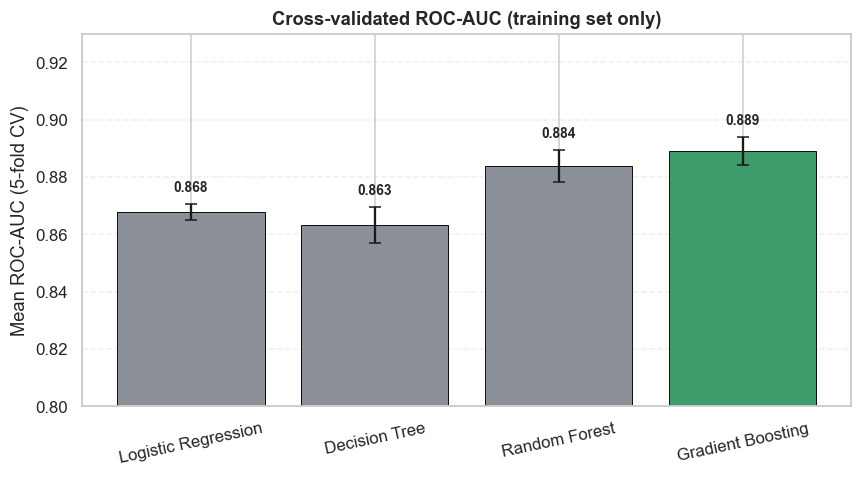

In [78]:
fig, ax = plt.subplots(figsize=(8, 4.5))

colors = [GREY,GREY, GREY, GREEN]

bars = ax.bar(
    cv_table.index,
    cv_table["roc_auc"],
    yerr=cv_table["roc_auc_std"],
    capsize=4,
    color=colors[:len(cv_table)],
    edgecolor="black",
    linewidth=0.6
)

# Add ROC-AUC values above the bars
ax.bar_label(bars, fmt="%.3f", padding=6, fontsize=9, fontweight="bold")

ax.set_ylim(0.8, 0.93)
ax.set_ylabel("Mean ROC-AUC (5-fold CV)")
ax.set_title("Cross-validated ROC-AUC (training set only)")

plt.xticks(rotation=12)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
CHOSEN_NAME = "Gradient Boosting"

chosen_pipe = build_pipeline(models[CHOSEN_NAME]).fit(raw_train, y_train)       
p_decline_chosen = chosen_pipe.predict_proba(raw_test)[:, 1]                   
pred_chosen = (p_decline_chosen >= 0.5).astype(int)

from sklearn.metrics import roc_auc_score
print(f"{CHOSEN_NAME} - test set (cut-off 0.5)")
print(f"ROC-AUC : {roc_auc_score(y_test, p_decline_chosen):.4f}   (Logistic Regression pipeline: {roc_auc_score(y_test, p_decline_pipe):.4f})")
print(f"Accuracy: {accuracy_score(y_test, pred_chosen):.4f}   Precision (Declined): {precision_score(y_test, pred_chosen):.4f}   Recall (Declined): {recall_score(y_test, pred_chosen):.4f}")

Gradient Boosting - test set (cut-off 0.5)
ROC-AUC : 0.8851   (Logistic Regression pipeline: 0.8674)
Accuracy: 0.8037   Precision (Declined): 0.8170   Recall (Declined): 0.7511


                   Predicted Approved  Predicted Declined
Actually Approved                1081                 190
Actually Declined                 281                 848


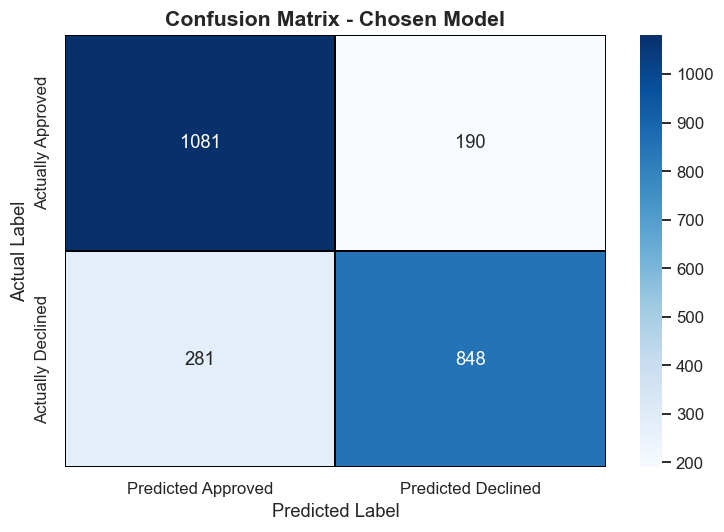

In [87]:
cm2 = confusion_matrix(y_test, pred_chosen)
print(pd.DataFrame(cm2, index=["Actually Approved", "Actually Declined"], columns=["Predicted Approved", "Predicted Declined"]))
cm2 = confusion_matrix(y_test, pred_chosen)
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm2,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="black",
    xticklabels=["Predicted Approved", "Predicted Declined"],
    yticklabels=["Actually Approved", "Actually Declined"]
)
plt.title("Confusion Matrix - Chosen Model", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [89]:
names = [n.split("__", 1)[1] for n in chosen_pipe.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(chosen_pipe.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
top8 = imp.head(8)
print("\nTop 8 feature importances:")
print(top8.round(3))


Top 8 feature importances:
delinquencies_24m                 0.304
credit_score                      0.290
foir                              0.287
years_in_current_job              0.029
is_ntc                            0.020
employment_type_Gig / Contract    0.019
loan_to_income                    0.016
employment_type_Salaried          0.015
dtype: float64


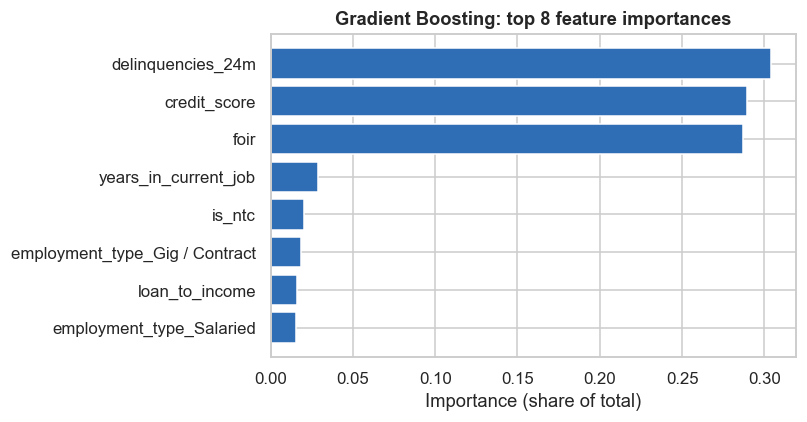

In [90]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(top8.index[::-1], top8.values[::-1], color=BLUE)
ax.set_xlabel("Importance (share of total)"); ax.set_title(f"{CHOSEN_NAME}: top 8 feature importances")
plt.tight_layout(); plt.show()

### 5.9 Findings

| Model (5-fold CV, training set) | ROC-AUC | Accuracy | Precision (Declined) | Recall (Declined) |
|---|---|---|---|---|
| Logistic Regression | 0.868 | 77.5% | 78.0% | 72.7% |
| Decision Tree (depth 5) | 0.863 | 78.2% | 80.8% | 70.5% |
| Random Forest | 0.884 | 79.5% | 79.6% | 75.9% |
| **Gradient Boosting** | **0.889** | **80.0%** | **81.2%** | 74.8% |

**Choice: Gradient Boosting.** It ranks applications best (AUC 0.889 vs 0.868 for logistic regression, about 2 points, well outside the ±0.003–0.006 fold-to-fold spread), and it also has the best accuracy and precision. On the untouched test set it holds up (AUC **0.885** vs 0.867; wrongly flags 190 good applicants at 0.5 vs 225 for logistic regression).

**Is the gain worth losing explainability?** For a credit decision, yes, but with conditions. A 2-point AUC gain matters here because the bank's lanes depend on how *cleanly* the model separates clear cases from borderline ones (the gain turns into about 300 more automated applications a month in 5.10). The explainability loss is smaller than it looks: three features carry **88% of the importance** (below), the same three the logistic regression ranked top. The bank should still keep logistic regression as the transparent **benchmark**, and produce **reason codes** for any auto-decline.

**Do the importances agree with 5.2 and 5.3?** Yes. **Delinquencies (30.4%), credit score (29.0%) and FOIR (28.7%)** dominate, matching the 650 score cliff and the 55% FOIR drop. Next come years in job (2.9%), new-to-credit (2.0%), Gig work (1.9%), loan-to-income (1.6%) and Salaried (1.5%), each small, though the Gig and Salaried flags again echo the employment-type gap. Impurity importances show *how much* a feature matters, not the *direction*, which is why the coefficients from 5.4 remain useful.

### 5.10 Design the two-lane pre-screener

In [97]:
def two_lane_search(p_approve, declined, max_wrong_decline=0.05, max_wrong_fast=0.05):
    """Grid-search (low, high) cut-offs on P(approval).
         auto-decline : P(approval) <  low   -> at most 5% of this lane may be applications the team APPROVED
         fast-track   : P(approval) >= high  -> at most 5% of this lane may be applications the team DECLINED
       Returns the pair that takes the largest share of applications out of the manual queue."""
    p_approve, approved = np.asarray(p_approve), 1 - np.asarray(declined)
    best = None
    for low in np.round(np.arange(0.01, 0.51, 0.01), 2):
        auto = p_approve < low
        if auto.sum() == 0 or approved[auto].mean() > max_wrong_decline:
            continue
        for high in np.round(np.arange(0.50, 1.00, 0.01), 2):
            fast = p_approve >= high
            if fast.sum() == 0 or (1 - approved[fast]).mean() > max_wrong_fast:
                continue
            total = auto.mean() + fast.mean()
            if best is None or total > best["automated_share"]:
                best = {"low": low, "high": high, "automated_share": total,
                        "auto_decline_share": auto.mean(), "fast_track_share": fast.mean(),
                        "review_share": 1 - total,
                        "wrong_in_auto_decline": approved[auto].mean(),
                        "wrong_in_fast_track": (1 - approved[fast]).mean(),
                        "n_auto": int(auto.sum()), "n_fast": int(fast.sum())}
    return best


lane_inputs = {"Logistic Regression": 1 - p_decline_pipe, CHOSEN_NAME: 1 - p_decline_chosen}
lanes = {name: two_lane_search(p, y_test) for name, p in lane_inputs.items()}

lane_table = pd.DataFrame(lanes).T[["low", "high", "auto_decline_share", "review_share", "fast_track_share",
                                    "wrong_in_auto_decline", "wrong_in_fast_track", "n_auto", "n_fast"]]
print((lane_table.astype({"low": float, "high": float, "auto_decline_share": float, "review_share": float, "fast_track_share": float,
                          "wrong_in_auto_decline": float, "wrong_in_fast_track": float}) .assign(
    auto_decline_share=lambda d: d.auto_decline_share * 100, review_share=lambda d: d.review_share * 100,
    fast_track_share=lambda d: d.fast_track_share * 100, wrong_in_auto_decline=lambda d: d.wrong_in_auto_decline * 100,
    wrong_in_fast_track=lambda d: d.wrong_in_fast_track * 100)).round(2).T)

                       Logistic Regression  Gradient Boosting
low                                   0.10               0.17
high                                  0.89               0.90
auto_decline_share                   15.21              24.25
review_share                         68.04              58.17
fast_track_share                     16.75              17.58
wrong_in_auto_decline                 4.66               4.81
wrong_in_fast_track                   4.73               3.79
n_auto                              365.00             582.00
n_fast                              402.00             422.00


In [99]:
impact = pd.DataFrame({
    name: {"auto-decline apps / month": r["auto_decline_share"] * APPS_PER_MONTH,
           "fast-track apps / month": r["fast_track_share"] * APPS_PER_MONTH,
           "apps leaving manual queue / month": r["automated_share"] * APPS_PER_MONTH,
           "analyst hours freed / month": hours_for(r["automated_share"])} for name, r in lanes.items()}).round(0)
impact["difference (chosen - LR)"] = impact[CHOSEN_NAME] - impact["Logistic Regression"]
print(impact)
print(f"\nBaseline: {APPS_PER_MONTH:,} apps x {REVIEW_MINUTES} min = {hours_for(1):,.0f} analyst hours per month if every application is reviewed manually.")

LIGHT_TOUCH_MIN = 5   # ASSUMPTION for illustration: a fast-track light-touch check takes ~5 minutes
for name, r in lanes.items():
    net = hours_for(r["auto_decline_share"]) + r["fast_track_share"] * APPS_PER_MONTH * (REVIEW_MINUTES - LIGHT_TOUCH_MIN) / 60
    print(f"{name}: net hours saved if fast-track still costs {LIGHT_TOUCH_MIN} min per app = {net:,.0f}")

                                   Logistic Regression  Gradient Boosting  difference (chosen - LR)
auto-decline apps / month                        456.0              728.0                     272.0
fast-track apps / month                          503.0              528.0                      25.0
apps leaving manual queue / month                959.0             1255.0                     296.0
analyst hours freed / month                      399.0              523.0                     124.0

Baseline: 3,000 apps x 25 min = 1,250 analyst hours per month if every application is reviewed manually.
Logistic Regression: net hours saved if fast-track still costs 5 min per app = 358
Gradient Boosting: net hours saved if fast-track still costs 5 min per app = 479


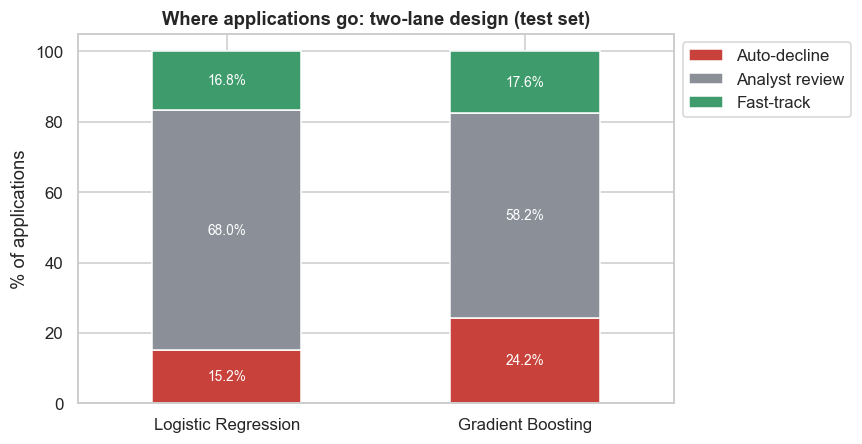

In [100]:
plot_df = pd.DataFrame({name: {"Auto-decline": r["auto_decline_share"] * 100,
                              "Analyst review": r["review_share"] * 100,
                              "Fast-track": r["fast_track_share"] * 100} for name, r in lanes.items()}).T

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_df.plot.bar(stacked=True, ax=ax, color=[RED, GREY, GREEN], rot=0, width=0.5)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
ax.set_ylabel("% of applications"); ax.set_title("Where applications go: two-lane design (test set)"); ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

In [101]:
# Stability check. The cut-offs above were tuned on the 2,400 test applications, so the realised error rates
# will look slightly flattering. Re-measure the SAME cut-offs on out-of-fold predictions for the 9,600 training applications.
def lane_rates(p_approve, declined, low, high):
    p_approve, approved = np.asarray(p_approve), 1 - np.asarray(declined)
    auto, fast = p_approve < low, p_approve >= high
    return approved[auto].mean() * 100, (1 - approved[fast]).mean() * 100, auto.mean() * 100, fast.mean() * 100

stab_rows, oof_p_approve = [], {}
for name, clf in {"Logistic Regression": models["Logistic Regression"], CHOSEN_NAME: models[CHOSEN_NAME]}.items():
    oof_decline = cross_val_predict(build_pipeline(clf), raw_train, y_train, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    oof_p_approve[name] = 1 - oof_decline
    lo, hi = lanes[name]["low"], lanes[name]["high"]
    wa, wf, sa, sf = lane_rates(1 - oof_decline, y_train, lo, hi)
    stab_rows.append({"model": name, "low": lo, "high": hi, "auto_decline_%": sa, "fast_track_%": sf,
                      "wrongly_auto_declined_%": wa, "wrongly_fast_tracked_%": wf})
print(pd.DataFrame(stab_rows).set_index("model").round(2))

                      low  high  auto_decline_%  fast_track_%  wrongly_auto_declined_%  wrongly_fast_tracked_%
model                                                                                                         
Logistic Regression  0.10  0.89           15.28         17.02                     4.36                    5.14
Gradient Boosting    0.17  0.90           23.60         18.10                     5.34                    3.51


In [ ]:
robust_rows, robust_lanes = [], {}
for name in lane_inputs:
    r = two_lane_search(oof_p_approve[name], y_train)                       
    robust_lanes[name] = r
    wa, wf, sa, sf = lane_rates(lane_inputs[name], y_test, r["low"], r["high"])   
    robust_rows.append({"model": name, "low": r["low"], "high": r["high"],
                        "TRAIN-OOF auto_decline_%": r["auto_decline_share"] * 100, "TRAIN-OOF fast_track_%": r["fast_track_share"] * 100,
                        "TRAIN-OOF wrong_auto_%": r["wrong_in_auto_decline"] * 100, "TRAIN-OOF wrong_fast_%": r["wrong_in_fast_track"] * 100,
                        "TEST auto_decline_%": sa, "TEST fast_track_%": sf, "TEST wrong_auto_%": wa, "TEST wrong_fast_%": wf})
robust_table = pd.DataFrame(robust_rows).set_index("model")
print(robust_table.round(2).T)

for name, r in robust_lanes.items():
    _, _, sa, sf = lane_rates(lane_inputs[name], y_test, r["low"], r["high"])
    print(f"{name}: on test -> {sa + sf:.1f}% of applications automated = ~{(sa + sf) / 100 * APPS_PER_MONTH:,.0f} apps and ~{hours_for((sa + sf) / 100):,.0f} analyst hours per month")

model                     Logistic Regression  Gradient Boosting
low                                      0.11               0.15
high                                     0.90               0.88
TRAIN-OOF auto_decline_%                16.24              22.24
TRAIN-OOF fast_track_%                  15.60              20.75
TRAIN-OOF wrong_auto_%                   4.68               4.73
TRAIN-OOF wrong_fast_%                   4.87               4.72
TEST auto_decline_%                     16.25              22.67
TEST fast_track_%                       15.67              20.29
TEST wrong_auto_%                        5.64               4.04
TEST wrong_fast_%                        4.26               5.34
Logistic Regression: on test -> 31.9% of applications automated = ~958 apps and ~399 analyst hours per month
Gradient Boosting: on test -> 43.0% of applications automated = ~1,289 apps and ~537 analyst hours per month


### 5.10 Findings

**Search on the test set (as specified)**

| | Logistic Regression | Gradient Boosting |
|---|---|---|
| Thresholds (auto-decline below / fast-track at or above) | 0.10 / 0.89 | 0.17 / 0.90 |
| Auto-decline lane | 15.2% | **24.2%** |
| Analyst review | 68.0% | **58.2%** |
| Fast-track lane | 16.8% | **17.6%** |
| Wrongly auto-declined · wrongly fast-tracked | 4.7% · 4.7% | 4.8% · 3.8% |
| Applications leaving the manual queue / month | 959 | **1,255** |
| Analyst hours freed / month (of 1,250) | 399 | **523** |

**The difference:** Gradient Boosting takes **about 296 more applications and 124 more analyst hours a month** out of the manual queue than logistic regression (about 42% vs 32% of the queue). Almost all of the gain is in the **auto-decline lane** (24.2% vs 15.2%), because the stronger model is confident about many more declines, while the fast-track lane is similar (17.6% vs 16.8%). Both models respect both 5% limits here. (If a fast-track light-touch check takes about 5 minutes, an illustrative assumption, net savings are about 479 vs 358 hours.)

**A stability warning, which matters.** These cut-offs were *tuned on* the 2,400 test applications, so their error rates look flattering. Re-measured on 9,600 out-of-fold training predictions, the same cut-offs show **5.3%** wrongly auto-declined for Gradient Boosting and **5.1%** wrongly fast-tracked for logistic regression, slightly *over* the limit. Tuning instead on the larger out-of-fold sample and checking once on the test set gives Gradient Boosting cut-offs of **0.15 / 0.88** that automate **43.0%** (22.7% + 20.3%) with 4.0% and 5.3% wrong rates on test, and logistic regression **0.11 / 0.90** that automate **31.9%** (with 5.6% and 4.3%). The conclusion (Gradient Boosting automates roughly **10 percentage points more**) holds either way, but the 5% limits can only be trusted to about **±1 point**.

### 5.11 Credit Policy Recommendation


In [103]:
REC_LOW, REC_HIGH = robust_lanes[CHOSEN_NAME]["low"], robust_lanes[CHOSEN_NAME]["high"]
p_app_test = 1 - p_decline_chosen
mix = df.loc[raw_test.index, ["gender", "employment_type", "is_ntc", "declined"]].copy()
mix["lane"] = np.select([p_app_test < REC_LOW, p_app_test >= REC_HIGH], ["Auto-decline", "Fast-track"], default="Analyst review")
print(f"Recommended cut-offs: auto-decline if P(approval) < {REC_LOW}, fast-track if P(approval) >= {REC_HIGH}\n")
print("Overall lane shares (%):")
print((mix["lane"].value_counts(normalize=True) * 100).round(1).to_string())

def lane_share(col):
    return (pd.crosstab(mix[col], mix["lane"], normalize="index") * 100).round(1)[["Auto-decline", "Analyst review", "Fast-track"]]
for col in ["gender", "employment_type", "is_ntc"]:
    print(f"\nLane share (%) by {col}:")
    print(lane_share(col))

Recommended cut-offs: auto-decline if P(approval) < 0.15, fast-track if P(approval) >= 0.88

Overall lane shares (%):
lane
Analyst review    57.0
Auto-decline      22.7
Fast-track        20.3

Lane share (%) by gender:
lane    Auto-decline  Analyst review  Fast-track
gender                                          
Female          24.0            57.9        18.1
Male            22.1            56.7        21.3

Lane share (%) by employment_type:
lane                        Auto-decline  Analyst review  Fast-track
employment_type                                                     
Business Owner                      20.8            59.3        19.9
Gig / Contract                      40.1            51.1         8.8
Salaried                            19.8            56.6        23.6
Self-Employed Professional          17.7            63.3        19.0

Lane share (%) by is_ntc:
lane    Auto-decline  Analyst review  Fast-track
is_ntc                                          
0         

**Answer.**

* **Main risk:** the `decision` column records what analysts decided, **not whether loans were repaid**. The model cannot know whether a fast-tracked loan will default, it has only six months of history, and any bias in past decisions is copied.
* **How close to the limit we are:** on the test set the lanes are at **4.0%** (auto-decline) and **5.3%** (fast-track) against the 5% limit. Cut-offs tuned on the small test set were **5.3%** wrong when re-measured on the larger training sample. So the limits are only reliable to about **one point**.
* **Always with a human:**
  * **New-to-credit applicants:** 1,039 applicants (8.7%) with no score. The model already sends **99.0%** of them to analysts, and their approval rate (53.9%) is close to a coin flip.
  * **High-income professionals:** 1,685 applicants (14%). The model is wrong **27%** of the time there, against 14 to 20% in the other segments, and their approval rate is 59%.

### Credit Policy Recommendation

I recommend the **Gradient Boosting** model with two cut-offs on its probability of approval: **auto-decline when it is below 0.15** (the model is at least 85% sure the application is a decline) and **fast-track when it is 0.88 or above**, which on held-out data handles **22.7%** and **20.3%** of applications, leaving **57.0%** with analysts as today. That removes about **1,290 of 3,000 monthly applications (43%) from the full manual queue and frees about 537 of 1,250 analyst hours**, roughly **330 more applications and 140 more hours** than the logistic regression two-lane design, which automates only about 32% (about 960 applications, 400 hours). The main risk of going live is that the model copies **past analyst decisions, not repayment outcomes**: it cannot know whether a fast-tracked loan will default, it has only six months of history, and the 5% limits hold only to about ±1 point (4.0% and 5.3% on test), so we are at the edge of the risk appetite rather than comfortably inside it. **New-to-credit applicants (99% routed to an analyst by the model already) and the high-income, large-ticket segment, where the model errs 27% of the time against 14–20% elsewhere, should always stay with a human**, as should anything near the 55% FOIR line. On fairness, gender is never an input and should never be, and the model does not widen the historical gap (auto-decline 15.6% for women vs 15.0% for men), but gig and contract workers are auto-declined at **40.1%** against 19.8% for salaried staff and fast-tracked only 8.8% of the time, so employment type is acting as a proxy that falls harder on women (21% of whom are gig workers). The bank should therefore **report monthly auto-decline, fast-track and wrong-lane rates by gender and employment type**, with a pre-agreed trigger (for example a gap of more than 2 points) that sends the cut-offs back for review, and explain every auto-decline with reason codes. Before full rollout I would run a **4–8 week shadow-mode pilot**, with the model scoring live applications while analysts decide exactly as today, to confirm on fresh data that both lanes stay within 5% (and tighten the cut-offs by a point or two if not), and to start tracking actual repayment of the fast-track lane.

### 5.12 Stretch (optional): Where does the model struggle?


In [104]:
seg_cols = ["monthly_income", "credit_score", "foir", "years_in_current_job", "age"]
seg = df[seg_cols].copy()
seg["credit_score"] = seg["credit_score"].fillna(seg["credit_score"].median())    # unscored applicants: median (flag lives in is_ntc)
seg_scaled = StandardScaler().fit_transform(seg)

from sklearn.metrics import silhouette_score
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(seg_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(seg_scaled, km.labels_, sample_size=4000, random_state=42))
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3)}).set_index("k").T.to_string())


  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


k                  2        3          4          5          6         7          8          9          10
inertia     48692.000  42957.0  38154.000  33721.000  30526.000  28638.00  27440.000  26308.000  25286.000
silhouette      0.211      0.2      0.209      0.179      0.179      0.17      0.168      0.164      0.159


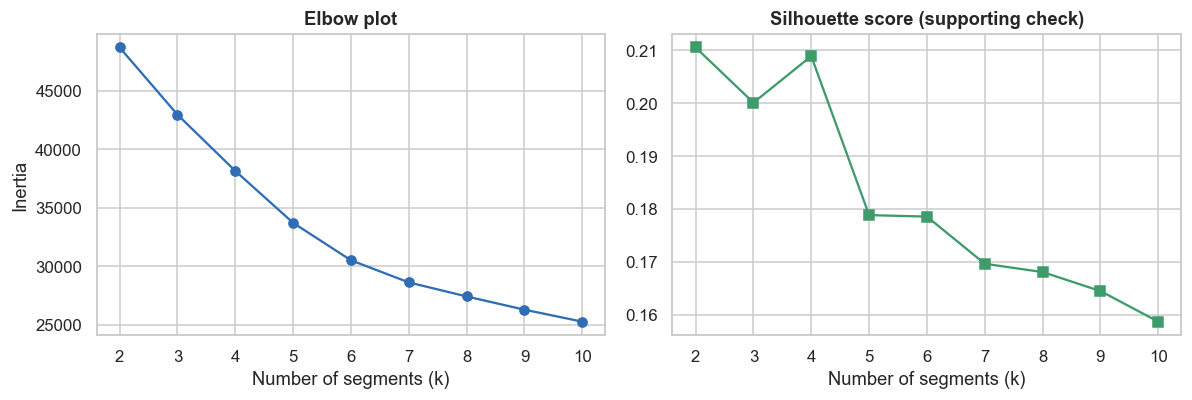

In [105]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(ks), inertia, marker="o", color=BLUE); ax[0].set_title("Elbow plot"); ax[0].set_xlabel("Number of segments (k)"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(ks), sil, marker="s", color=GREEN); ax[1].set_title("Silhouette score (supporting check)"); ax[1].set_xlabel("Number of segments (k)")
plt.tight_layout(); plt.show()

In [ ]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(seg_scaled)
df["segment"] = km.labels_                        

profile = df.groupby("segment").agg(applicants=("segment", "size"),
                                    median_income=("monthly_income", "median"),
                                    median_score=("credit_score", "median"),
                                    median_foir=("foir", "median"),
                                    mean_job_years=("years_in_current_job", "mean"),
                                    mean_age=("age", "mean"),
                                    no_score_share=("is_ntc", "mean"),
                                    gig_share=("employment_type", lambda s: (s == "Gig / Contract").mean()),
                                    approval_rate=("approved", "mean"))
test_seg = pd.DataFrame({"segment": df.loc[raw_test.index, "segment"].values, "error": (pred_chosen != y_test.values).astype(int),
                         "wrongly_declined": ((pred_chosen == 1) & (y_test.values == 0)).astype(int),
                         "wrongly_approved": ((pred_chosen == 0) & (y_test.values == 1)).astype(int)})
profile["test_n"] = test_seg.groupby("segment").size()
profile["model_error_rate"] = test_seg.groupby("segment")["error"].mean()

name_map = {s: "Early-career mainstream" for s in profile.index}
name_map[profile["median_foir"].idxmax()] = "Over-stretched borrowers"
name_map[profile["median_income"].idxmax()] = "High-income professionals"
name_map[profile["mean_job_years"].idxmax()] = "Established stable earners"
assert len(set(name_map.values())) == K, "segment names collided - check the profile table"
profile.insert(0, "segment_name", profile.index.map(name_map))
df["segment_name"] = df["segment"].map(name_map)
print(profile.round(2).to_string())



                       segment_name  applicants  median_income  median_score  median_foir  mean_job_years  mean_age  no_score_share  gig_share  approval_rate  test_n  model_error_rate
segment                                                                                                                                                                                
0           Early-career mainstream        5869        42500.0         714.0         0.28            2.35     29.37            0.12       0.21           0.54    1159              0.20
1          Over-stretched borrowers        1878        48500.0         731.0         0.65            3.10     33.70            0.03       0.18           0.23     391              0.14
2        Established stable earners        2568        54500.0         743.0         0.29            7.62     39.50            0.06       0.07           0.68     531              0.19
3         High-income professionals        1685       112500.0         730.0    

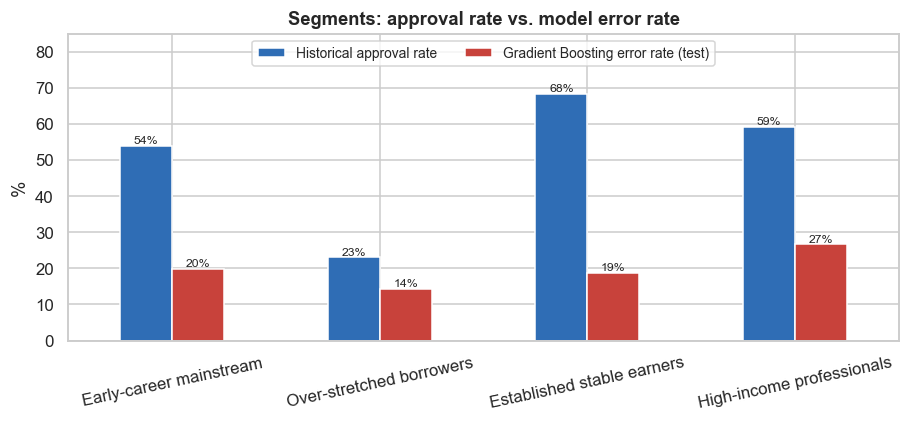


Lane share (%) by segment, recommended cut-offs (test set):
lane                        Auto-decline  Analyst review  Fast-track
segment_name                                                        
Early-career mainstream             21.0            60.4        18.6
Established stable earners          10.9            54.0        35.0
High-income professionals           13.5            63.3        23.2
Over-stretched borrowers            51.2            46.0         2.8


In [109]:
fig, ax = plt.subplots(figsize=(8.5, 4))
plot_seg = profile.set_index("segment_name")[["approval_rate", "model_error_rate"]] * 100
plot_seg.columns = ["Historical approval rate", f"{CHOSEN_NAME} error rate (test)"]
plot_seg.plot.bar(ax=ax, color=[BLUE, RED], rot=12)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", fontsize=8)
ax.set_ylim(0, 85); ax.legend(loc="upper center", ncol=2, fontsize=9)
ax.set_ylabel("%"); ax.set_xlabel(""); ax.set_title("Segments: approval rate vs. model error rate")
plt.tight_layout(); plt.show()

# Which lane does each segment land in under the recommended cut-offs from Step 5.11?
seg_lane = pd.DataFrame({"segment_name": df.loc[raw_test.index, "segment_name"].values,
                         "lane": np.select([(1 - p_decline_chosen) < REC_LOW, (1 - p_decline_chosen) >= REC_HIGH],
                                           ["Auto-decline", "Fast-track"], default="Analyst review")})
print("\nLane share (%) by segment, recommended cut-offs (test set):")
print((pd.crosstab(seg_lane["segment_name"], seg_lane["lane"], normalize="index") * 100).round(1)[["Auto-decline", "Analyst review", "Fast-track"]])

### 5.12 Findings

**Choosing k.** The elbow plot is gentle: inertia keeps falling smoothly, with the drops shrinking from about k = 6–7 onward, so there is no sharp break. The silhouette score is flat at about 0.21 for k = 2–4 and weaker for k = 5 and above (0.18 or lower), so adding segments beyond 4 buys little separation. I chose **k = 4** as the most interpretable split, which is a judgement call rather than a clear statistical optimum.

| Segment | Applicants | Profile | Approval rate | Model error rate (test) |
|---|---|---|---|---|
| **Early-career mainstream** | 5,869 | Median income 42,500, score 714, FOIR 0.28, about 2.4 years in job, age 29, 21% gig | 54% | 20% |
| **Over-stretched borrowers** | 1,878 | **FOIR 0.65**, score 731 | **23%** | **14%** |
| **Established stable earners** | 2,568 | About 7.6 years in job, age 40, best score (743) | **68%** | 19% |
| **High-income professionals** | 1,685 | **Median income 112,500**, 2% gig | 59% | **27%** |

**Which segment should always stay with a human?** The **High-income professionals**. The model is wrong **27%** of the time there, against 14–20% elsewhere, and their approval rate (59%) is close to a coin-flip. These are large-ticket applications where the decision turns on things the dataset barely captures (income verification, loan size, business or professional context), so they are poor candidates for automation. By contrast the **Over-stretched borrowers** are where the model is most reliable (14% error, 23% approval): clear affordability failures, and a natural source of auto-declines, as the lane table above shows (51% of them are auto-declined, 3% fast-tracked).